# 02_Ripple_protect

In [27]:
# --- 12.0 Configuration -----------------------------------------------------------
import os, json, numpy as np, pandas as pd

# Scope: One-shot, domain prompt, single iteration.
ONESHOT_SHOT   = "one"
ONESHOT_PROMPT = "domain"
ITERATION      = 0            # single iteration; mixing iterations would duplicate sample_ids
WRONG_TOKEN    = "__wrong__"

# Reuse existing saved predictions (no LLM rerun). First existing file wins.
PREDICTION_CSV_CANDIDATES = [
    run_path("CrisisLexT26_one_shot_domain_predictions.csv"),   # one-shot + domain, all iterations (has correct+wrong)
    run_path("CrisisLexT26_all_predictions_per_instance.csv"),  # everything; filtered below
]


# Protect memory: ONE GLOBAL pool = ALL W0-correct samples in scope. No cosine / MiniLM /
# same-class / top-k / N_PROTECT selection is used to decide Protect membership.

# Output files.
OUT_RIPPLE   = run_path("CrisisLexT26_ripple_sets.csv")
OUT_PROTECT  = run_path("CrisisLexT26_protect_sets.csv")
OUT_SUMMARY  = run_path("CrisisLexT26_ripple_protect_summary.csv")

print(f"Scope: shot={ONESHOT_SHOT!r} prompt={ONESHOT_PROMPT!r} iteration={ITERATION}")
print("Ripple grouping: by true_label only "
      "(one group per unique true_label; no similarity / threshold / min-size)")
print("Protect: ONE GLOBAL memory = ALL W0-correct samples in scope")



Scope: shot='one' prompt='domain' iteration=0
Ripple grouping: by true_label only (one group per unique true_label; no similarity / threshold / min-size)
Protect: ONE GLOBAL memory = ALL W0-correct samples in scope


In [28]:
# --- 12.1 Load saved One-shot predictions (reuse; no reclassification) ------------
def _load_predictions():
    for path in PREDICTION_CSV_CANDIDATES:
        if os.path.exists(path):
            df = pd.read_csv(path, dtype=str, keep_default_na=False)
            print(f"[load] using saved predictions: {path}  ({len(df)} rows)")
            return df, path
    if "pred_df" in globals() and isinstance(globals()["pred_df"], pd.DataFrame):
        print("[load] no CSV found; using in-memory pred_df")
        return globals()["pred_df"].astype(str), "<in-memory pred_df>"
    if "PER_INSTANCE_RECORDS" in globals() and len(globals()["PER_INSTANCE_RECORDS"]) > 0:
        print("[load] no CSV found; using in-memory PER_INSTANCE_RECORDS")
        return pd.DataFrame(globals()["PER_INSTANCE_RECORDS"]).astype(str), "<in-memory records>"
    raise FileNotFoundError(
        "No saved prediction CSV found. Run Section 10-11 once to produce "
        + PREDICTION_CSV_CANDIDATES[0] + "."
    )

pred_raw, PRED_SOURCE = _load_predictions()
print("columns:", list(pred_raw.columns))


[load] using saved predictions: /scratch/project_2019963/ablation/Wo_KL_CrisisLext26/Crisislext26_500_run/CrisisLexT26_one_shot_domain_predictions.csv  (500 rows)
columns: ['dataset', 'sample_id', 'text', 'true_label', 'predicted_label', 'is_correct', 'is_misclassified', 'invalid_model_output', 'shot', 'prompt', 'iteration', 'raw_model_output', 'exact_messages_json', 'exemplars_json']


In [29]:
# --- 12.2 Filter to scope, drop invalid outputs, split correct vs misclassified ---
REQUIRED = {"sample_id","text","true_label","predicted_label","shot","prompt","iteration"}
missing = REQUIRED - set(pred_raw.columns)
assert not missing, f"Saved predictions missing required columns: {missing}"

def _to_bool(s):
    return s.astype(str).str.strip().str.lower().isin(["true","1","yes"])

d = pred_raw.copy()
d["iteration"] = d["iteration"].astype(str).str.strip()
scoped = d[(d["shot"].astype(str)==ONESHOT_SHOT) &
           (d["prompt"].astype(str)==ONESHOT_PROMPT) &
           (d["iteration"]==str(ITERATION))].copy()

valid_mask = scoped["predicted_label"].astype(str) != WRONG_TOKEN
if "invalid_model_output" in scoped.columns:
    valid_mask &= ~_to_bool(scoped["invalid_model_output"])
valid_df = scoped[valid_mask].copy().reset_index(drop=True)

valid_df["true_label"]      = valid_df["true_label"].astype(str)
valid_df["predicted_label"] = valid_df["predicted_label"].astype(str)
valid_df["is_correct"]       = valid_df["predicted_label"] == valid_df["true_label"]
valid_df["is_misclassified"] = ~valid_df["is_correct"]

dup = valid_df["sample_id"].duplicated().sum()
assert dup == 0, f"sample_id not unique in scope ({dup} duplicates) — check ITERATION."

mis_df     = valid_df[valid_df["is_misclassified"]].copy()   # Ripple pool
correct_df = valid_df[valid_df["is_correct"]].copy()          # Protect pool

print(f"scoped rows: {len(scoped)} -> valid: {len(valid_df)}")
print(f"  misclassified (Ripple pool): {len(mis_df)}")
print(f"  correct       (Protect pool): {len(correct_df)}")
print("\nMisclassified per true_label:")
print(mis_df["true_label"].value_counts().to_string())


scoped rows: 500 -> valid: 500
  misclassified (Ripple pool): 296
  correct       (Protect pool): 204

Misclassified per true_label:
true_label
other_relevant_information             128
affected_individual                     79
sympathy_and_support                    33
caution_and_advice                      25
donation_and_volunteering               14
not_humanitarian                        12
infrastructure_and_utilities_damage      5


In [30]:
# --- 12.4 Build Ripple GROUPS by true_label ONLY (no semantic / embedding) --------
# Ripple construction groups misclassified samples purely by their ground-truth
# true_label. Each unique true_label -> exactly one Ripple group, containing every
# misclassified sample of that class. No embeddings, no cosine similarity, no
# threshold, no connected-components clustering, and no minimum-size filtering are
# used to form or split groups.
ripple_rows = []
group_meta  = {}                 # ripple_group_id -> {true_label, member_ids}
gid = 0
for c in sorted(mis_df["true_label"].unique()):
    members  = mis_df[mis_df["true_label"] == c]
    comp_ids = sorted(members["sample_id"].astype(str).tolist())   # ALL misclassified of this class
    group_meta[gid] = {"true_label": c, "member_ids": comp_ids}
    for sid in comp_ids:
        row = members[members["sample_id"] == sid].iloc[0]
        ripple_rows.append({
            "ripple_group_id": gid,
            "sample_id": sid,
            "text": row["text"],
            "true_label": c,
            "predicted_label": row["predicted_label"],
            "iteration": ITERATION,
            "prompt": ONESHOT_PROMPT,
        })
    gid += 1

ripple_sets = pd.DataFrame(ripple_rows)
print(f"Ripple groups: {len(group_meta)} | Ripple samples grouped: {len(ripple_sets)}")
if len(ripple_sets):
    print(ripple_sets.groupby("true_label")["ripple_group_id"].nunique()
          .rename("n_groups").to_string())

# ---- [check] Ripple construction invariants -------------------------------------
_mis_tl = dict(zip(mis_df["sample_id"].astype(str), mis_df["true_label"].astype(str)))
# (1) every Ripple group contains exactly one unique true_label
for _gid, _meta in group_meta.items():
    _labels = {_mis_tl[_m] for _m in _meta["member_ids"]}
    assert len(_labels) == 1, (
        f"Ripple group {_gid} contains multiple true labels: {_labels}"
    )
if len(ripple_sets):
    assert (ripple_sets.groupby("ripple_group_id")["true_label"].nunique() == 1).all(), (
        "A Ripple group contains multiple true labels."
    )
# (2) each unique true_label maps to exactly one Ripple group (bijection)
_group_labels = [m["true_label"] for m in group_meta.values()]
assert len(_group_labels) == len(set(_group_labels)), (
    "A true_label is split across multiple Ripple groups."
)
assert set(_group_labels) == set(mis_df["true_label"].astype(str).unique()), (
    "Ripple groups do not cover exactly the set of misclassified true_labels."
)
# (3) all misclassified samples are grouped (nothing dropped)
assert len(ripple_sets) == len(mis_df), (
    "Not all misclassified samples were placed into a Ripple group."
)
print("[check] each unique true_label -> exactly one Ripple group: OK")
print("[check] every Ripple group contains all its class's misclassified samples: OK")


Ripple groups: 7 | Ripple samples grouped: 296
true_label
affected_individual                    1
caution_and_advice                     1
donation_and_volunteering              1
infrastructure_and_utilities_damage    1
not_humanitarian                       1
other_relevant_information             1
sympathy_and_support                   1
[check] each unique true_label -> exactly one Ripple group: OK
[check] every Ripple group contains all its class's misclassified samples: OK


In [31]:
# Build Ripple groups by true_label
# Each unique true_label corresponds to one Ripple group containing
# all misclassified samples belonging to that class.
protect_cols = ["sample_id", "text", "true_label", "predicted_label", "iteration", "prompt"]
protect_rows = []
for _, r in correct_df.iterrows():
    protect_rows.append({
        "sample_id": str(r["sample_id"]),
        "text": r["text"],
        "true_label": str(r["true_label"]),
        "predicted_label": str(r["predicted_label"]),
        "iteration": ITERATION,
        "prompt": ONESHOT_PROMPT,
    })
protect_sets = pd.DataFrame(protect_rows, columns=protect_cols)
print(f"Protect (GLOBAL memory) = ALL W0-correct samples in scope: {len(protect_sets)} samples")


Protect (GLOBAL memory) = ALL W0-correct samples in scope: 204 samples


In [32]:
# --- 12.6 Summary table + save all outputs ----------------------------------------
GLOBAL_PROTECT_SIZE = int(len(protect_sets))
summary_rows = []
for gid, meta in group_meta.items():
    summary_rows.append({
        "ripple_group_id": gid,
        "true_label": meta["true_label"],
        "ripple_size": len(meta["member_ids"]),
        "protect_pool_size": GLOBAL_PROTECT_SIZE,   # ONE global Protect memory (same for all groups)
    })

summary_cols = ["ripple_group_id","true_label","ripple_size","protect_pool_size"]
summary = pd.DataFrame(summary_rows, columns=summary_cols)
if len(summary):
    summary = summary.sort_values("ripple_group_id").reset_index(drop=True)

ripple_cols  = ["ripple_group_id","sample_id","text","true_label","predicted_label",
                "iteration","prompt"]
protect_cols = ["sample_id","text","true_label","predicted_label","iteration","prompt"]

(ripple_sets.reindex(columns=ripple_cols) if len(ripple_sets)
 else pd.DataFrame(columns=ripple_cols)).to_csv(OUT_RIPPLE, index=False)
(protect_sets.reindex(columns=protect_cols) if len(protect_sets)
 else pd.DataFrame(columns=protect_cols)).to_csv(OUT_PROTECT, index=False)
summary.to_csv(OUT_SUMMARY, index=False)

print("Saved:")
print(f"  {OUT_RIPPLE}   ({len(ripple_sets)} rows)")
print(f"  {OUT_PROTECT}  ({len(protect_sets)} rows, GLOBAL Protect memory)")
print(f"  {OUT_SUMMARY}  ({len(summary)} groups)")
if len(summary) == 0:
    print("\n(No misclassified samples in scope, so no Ripple groups — "
          "ripple/summary CSVs are written with headers only.)")
else:
    display(summary)


Saved:
  /scratch/project_2019963/ablation/Wo_KL_CrisisLext26/Crisislext26_500_run/CrisisLexT26_ripple_sets.csv   (296 rows)
  /scratch/project_2019963/ablation/Wo_KL_CrisisLext26/Crisislext26_500_run/CrisisLexT26_protect_sets.csv  (204 rows, GLOBAL Protect memory)
  /scratch/project_2019963/ablation/Wo_KL_CrisisLext26/Crisislext26_500_run/CrisisLexT26_ripple_protect_summary.csv  (7 groups)


,ripple_group_id,true_label,ripple_size,protect_pool_size
0,0,affected_individual,79,204
1,1,caution_and_advice,25,204
2,2,donation_and_volunteering,14,204
3,3,infrastructure_and_utilities_damage,5,204
4,4,not_humanitarian,12,204
5,5,other_relevant_information,128,204
6,6,sympathy_and_support,33,204


In [33]:
# --- 12.7 Sanity checks (Ripple by true_label; Protect = ALL W0-correct global) ---
mis_ids     = set(mis_df["sample_id"].astype(str))       # W0-misclassified in scope
correct_ids = set(correct_df["sample_id"].astype(str))   # W0-correct in scope
ripple_ids  = set(ripple_sets["sample_id"].astype(str)) if len(ripple_sets) else set()
protect_ids = set(protect_sets["sample_id"].astype(str)) if len(protect_sets) else set()

# (a) no duplicate sample IDs in either set
if len(ripple_sets):
    assert not ripple_sets["sample_id"].astype(str).duplicated().any(), "duplicate Ripple sample IDs"
if len(protect_sets):
    assert not protect_sets["sample_id"].astype(str).duplicated().any(), "duplicate Protect sample IDs"

# (b) Ripple IDs == ALL W0-misclassified IDs ; Protect IDs == ALL W0-correct IDs (in scope)
assert ripple_ids == mis_ids,      "Ripple IDs != all W0-misclassified IDs in scope"
assert protect_ids == correct_ids, "Protect IDs != all W0-correct IDs in scope"

# (c) Ripple and Protect are disjoint
assert not (ripple_ids & protect_ids), "Ripple ∩ Protect is non-empty"

# (d) Ripple grouping invariants (construction is unchanged)
if len(ripple_sets):
    # every misclassified sample appears in exactly one Ripple group
    grp_of = ripple_sets.groupby("sample_id")["ripple_group_id"].nunique()
    assert (grp_of == 1).all(), "a misclassified sample appears in >1 Ripple group"
    assert len(ripple_sets) == len(mis_ids), "not every misclassified sample is grouped exactly once"
    # every Ripple group contains exactly one true_label
    assert (ripple_sets.groupby("ripple_group_id")["true_label"].nunique() == 1).all(), \
        "a Ripple group contains multiple true_labels"
    # every true_label maps to exactly one Ripple group (bijection)
    assert (ripple_sets.groupby("true_label")["ripple_group_id"].nunique() == 1).all(), \
        "a true_label maps to multiple Ripple groups"
    _labels = [m["true_label"] for m in group_meta.values()]
    assert len(_labels) == len(set(_labels)) == len(set(mis_df["true_label"].astype(str))), \
        "Ripple groups are not a bijection with the misclassified true_labels"

# (e) Protect coverage = 100% of W0-correct samples
coverage = (len(protect_ids) / len(correct_ids)) if correct_ids else 1.0
assert abs(coverage - 1.0) < 1e-12, \
    f"Protect coverage != 100% ({len(protect_ids)}/{len(correct_ids)})"

total = len(valid_df)
print("ALL SANITY CHECKS PASSED.")
print(f"  Total valid (in scope)   : {total}")
print(f"  W0 wrong  / Ripple       : {len(mis_ids)}")
print(f"  W0 correct / Protect     : {len(correct_ids)}")
print(f"  Protect coverage         : {len(protect_ids)}/{len(correct_ids)} = {coverage*100:.1f}%")
print(f"  Ripple ∩ Protect         : {len(ripple_ids & protect_ids)}")


ALL SANITY CHECKS PASSED.
  Total valid (in scope)   : 500
  W0 wrong  / Ripple       : 296
  W0 correct / Protect     : 204
  Protect coverage         : 204/204 = 100.0%
  Ripple ∩ Protect         : 0


In [34]:
# --- 12.8 Inspect example Ripple groups + global Protect memory --------------------
def _short(t, n=150):
    t = str(t).replace("\n", " ")
    return t if len(t) <= n else t[:n] + "..."

if len(summary) == 0:
    print("No Ripple groups were formed (no misclassified samples in the current scope).")
else:
    show = summary.sort_values("ripple_size", ascending=False)["ripple_group_id"].tolist()[:4]
    for gid in show:
        meta = group_meta[gid]
        print("="*84)
        print(f"RIPPLE GROUP {gid} | true_label={meta['true_label']} "
              f"| size={len(meta['member_ids'])}")
        rg = ripple_sets[ripple_sets["ripple_group_id"] == gid]
        for _, r in rg.iterrows():
            print(f"  [MIS ] id={r['sample_id']:<14} pred={r['predicted_label']:<26}")
            print(f"         {_short(r['text'])}")

print("="*84)
print(f"GLOBAL PROTECT MEMORY (ALL W0-correct samples): {len(protect_sets)} samples")
for _, r in protect_sets.head(8).iterrows():
    print(f"  [KEEP] id={r['sample_id']:<14} true={r['true_label']:<26} pred={r['predicted_label']:<26}")
    print(f"         {_short(r['text'])}")
if len(protect_sets) > 8:
    print(f"  ... and {len(protect_sets) - 8} more")

print("\nStopping here as requested: Ripple sets + GLOBAL Protect memory built and saved.")
print("FiNE localization and model editing are NOT implemented in this section.")


RIPPLE GROUP 5 | true_label=other_relevant_information | size=128
  [MIS ] id=207588310409953280 pred=sympathy_and_support      
         RT @MimiSimpsonGrey: @CodySimpson YOU KNOW WHAT SUCKS? THE FACT THAT YOU IGNORE US IN ITALY, THIS EARTHQUAKE IS DEVASTING US AND YOU DON ...
  [MIS ] id=214826689233027072 pred=caution_and_advice        
         RT @timmytink: Colorado wildfire: Extreme weather conditions stoke High Park Fire, tax firefighters http://t.co/TIIaLAVY via @denverpost
  [MIS ] id=217853101871341568 pred=not_humanitarian          
         All these fires in Colorado, and I'm going there in July! #freakedout 😳
  [MIS ] id=217953932943687680 pred=infrastructure_and_utilities_damage
         RT @nprnews 'Epic' Wildfire Sends Tens Of Thousands Scrambling For Safety In Colorado http://t.co/tgFtU5Sz
  [MIS ] id=217997121712947201 pred=not_humanitarian          
         Good morning - 6pm producer Duncan Shaw here with the morning news meeting.  We'll be covering the #cofire a

In [35]:
# --- 12.9 Show results: Ripple sets & GLOBAL Protect memory -----------------------
# Uses the in-memory dataframes if present, otherwise reads the saved CSVs,
# so it runs both right after Section 12 and standalone.
import os
import pandas as pd

def _get(mem_name, csv_path):
    obj = globals().get(mem_name)
    if isinstance(obj, pd.DataFrame):
        return obj.copy()
    return pd.read_csv(csv_path) if os.path.exists(csv_path) else pd.DataFrame()

_r_ripple  = _get("ripple_sets",  run_path("CrisisLexT26_ripple_sets.csv"))
_r_protect = _get("protect_sets", run_path("CrisisLexT26_protect_sets.csv"))
assert len(_r_ripple), "No Ripple rows found (run Section 12 first, or check the CSV path)."

# One row per Ripple group: true_label, ripple size. Protect is a single GLOBAL pool.
_r_grp = (_r_ripple.groupby(["ripple_group_id", "true_label"])
                   .size().rename("ripple_size").reset_index())
_r_grp = _r_grp.sort_values("ripple_group_id").reset_index(drop=True)

print(f"Ripple groups: {_r_grp['ripple_group_id'].nunique()} | "
      f"unique true_labels: {_r_ripple['true_label'].nunique()} | "
      f"misclassified grouped: {len(_r_ripple)}")
print(f"GLOBAL Protect memory: {len(_r_protect)} W0-correct samples "
      f"(one pool shared by all groups)\n")
print("Per-group result (each true_label = exactly one Ripple group):")
print(_r_grp.to_string(index=False))

# Invariant check on the actual result
_pl = _r_ripple.groupby("true_label")["ripple_group_id"].nunique()
assert (_pl == 1).all(), "Some true_label maps to more than one Ripple group!"
assert (_r_ripple.groupby("ripple_group_id")["true_label"].nunique() == 1).all(), \
    "Some Ripple group mixes true_labels!"
print("\n[invariant] each unique true_label -> exactly one Ripple group "
      "containing all its misclassified samples: OK")

# A few example groups with their members
def _short(t, n=120):
    t = str(t).replace("\n", " ")
    return t if len(t) <= n else t[:n] + "..."
print("\nExample groups:")
for gid in _r_grp.sort_values("ripple_size", ascending=False)["ripple_group_id"].tolist()[:3]:
    g = _r_ripple[_r_ripple["ripple_group_id"] == gid]
    print("=" * 80)
    print(f"RIPPLE GROUP {gid} | true_label={g['true_label'].iloc[0]} | size={len(g)}")
    for _, r in g.iterrows():
        print(f"  id={str(r['sample_id']):<12} pred={str(r['predicted_label']):<20} {_short(r['text'])}")


Ripple groups: 7 | unique true_labels: 7 | misclassified grouped: 296
GLOBAL Protect memory: 204 W0-correct samples (one pool shared by all groups)

Per-group result (each true_label = exactly one Ripple group):
 ripple_group_id                          true_label  ripple_size
               0                 affected_individual           79
               1                  caution_and_advice           25
               2           donation_and_volunteering           14
               3 infrastructure_and_utilities_damage            5
               4                    not_humanitarian           12
               5          other_relevant_information          128
               6                sympathy_and_support           33

[invariant] each unique true_label -> exactly one Ripple group containing all its misclassified samples: OK

Example groups:
RIPPLE GROUP 5 | true_label=other_relevant_information | size=128
  id=207588310409953280 pred=sympathy_and_support RT @MimiSimpsonGre

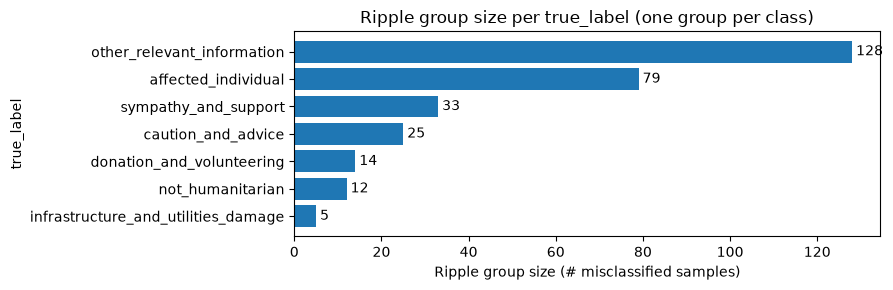

In [36]:
# --- 12.9b Optional chart: Ripple group size per true_label -----------------------
import matplotlib.pyplot as plt

_order = _r_grp.sort_values("ripple_size", ascending=False)
fig, ax = plt.subplots(figsize=(9, max(3, 0.4 * len(_order))))
ax.barh(_order["true_label"].astype(str), _order["ripple_size"])
ax.invert_yaxis()
ax.set_xlabel("Ripple group size (# misclassified samples)")
ax.set_ylabel("true_label")
ax.set_title("Ripple group size per true_label (one group per class)")
for _y, _v in enumerate(_order["ripple_size"]):
    ax.text(_v, _y, f" {int(_v)}", va="center")
plt.tight_layout()
plt.show()
